# Module 03 — Exercises — Solutions

Exercises for **Module 03 — Eigenvalues, SVD and PCA**. They roughly follow the
[concept guide](README.md): eigenvalues by hand, the spectral theorem, truncated SVD, power
iteration and PageRank, PCA, the pseudo-inverse, conditioning, ridge regression through the
SVD, two conceptual questions and a mini-project on latent-factor recommendation.
Use only NumPy (plus the scikit-learn objects named in a prompt) and keep everything seeded.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_wine
from sklearn.decomposition import PCA
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Eigenvalues of a 2x2 matrix by hand  `★☆☆`

Implement `eig2x2(A)` that returns the two eigenvalues of a real $2\times2$ matrix `A`
as a NumPy array **sorted in descending order**, using only the characteristic polynomial

$$\lambda^2 - \operatorname{tr}(A)\,\lambda + \det(A) = 0$$

and the quadratic formula. Do **not** call anything from `np.linalg`. You may assume the
eigenvalues are real (discriminant $\ge 0$).

In [3]:
def eig2x2(A):
    tr = A[0, 0] + A[1, 1]
    det = A[0, 0] * A[1, 1] - A[0, 1] * A[1, 0]
    disc = np.sqrt(tr ** 2 - 4 * det)
    return np.array([(tr + disc) / 2, (tr - disc) / 2])

**Check your answer:**

In [4]:
try:
    got = eig2x2(np.array([[4., 1.], [2., 3.]]))
except Exception:
    got = None
check_close('eigenvalues of [[4,1],[2,3]] are 5 and 2', got, np.array([5., 2.]))
try:
    got_sym = eig2x2(np.array([[2., 1.], [1., 2.]]))
except Exception:
    got_sym = None
check_close('eigenvalues of [[2,1],[1,2]] are 3 and 1', got_sym, np.array([3., 1.]))
try:
    got_hidden = eig2x2(np.array([[1., 4.], [2., 3.]]))
except Exception:
    got_hidden = None
check_hash('hidden: eigenvalues of [[1,4],[2,3]]', got_hidden, '45f8a93c2836fbf1')

✅ eigenvalues of [[4,1],[2,3]] are 5 and 2
✅ eigenvalues of [[2,1],[1,2]] are 3 and 1
✅ hidden: eigenvalues of [[1,4],[2,3]]


True

**Why this works**

For a $2\times2$ matrix the characteristic polynomial is fully determined by the trace and
the determinant, and the quadratic formula gives $\lambda = \tfrac12\left(\operatorname{tr} \pm
\sqrt{\operatorname{tr}^2 - 4\det}\right)$. The eigenvalues sum to the trace and multiply to
the determinant — a quick sanity check on any hand calculation. The hidden case has a
negative eigenvalue ($5$ and $-1$ for trace 4, determinant $-5$); a common wrong turn is to
sort by absolute value or to forget that the determinant can be negative.

## Exercise 2 — Spectral theorem and positive semidefiniteness  `★☆☆`

Implement two functions for a real **symmetric** matrix `A`:

* `spectral(A)` returns `(lam, Q)` where `lam` holds the eigenvalues **sorted in descending
  order** and the columns of `Q` are the matching **orthonormal** eigenvectors, so that
  `Q @ np.diag(lam) @ Q.T` reconstructs `A`. Use `np.linalg.eigh` (which returns ascending order).
* `is_psd(A, tol=1e-10)` returns a Python `bool`: `True` if every eigenvalue is $\ge -\text{tol}$.

In [5]:
def spectral(A):
    lam, Q = np.linalg.eigh(A)
    order = np.argsort(-lam)
    return lam[order], Q[:, order]

def is_psd(A, tol=1e-10):
    lam, _ = spectral(A)
    return bool(lam.min() >= -tol)

**Check your answer:**

In [6]:
_g = np.random.default_rng(11)
_B = _g.normal(size=(4, 4)); _S = _B @ _B.T
try:
    lam_s, Q_s = spectral(_S)
except Exception:
    lam_s, Q_s = None, None
check('eigenvalues sorted in descending order', lam_s is not None and np.all(np.diff(lam_s) <= 0))
check('Q is orthonormal (Q^T Q = I)', Q_s is not None and np.allclose(Q_s.T @ Q_s, np.eye(4)))
check('Q diag(lam) Q^T reconstructs A', Q_s is not None and np.allclose(Q_s @ np.diag(lam_s) @ Q_s.T, _S))
try:
    psd_a = is_psd(np.array([[2., 1.], [1., 2.]]))
    psd_b = is_psd(np.array([[1., 2.], [2., 1.]]))
    psd_c = is_psd(_S)
except Exception:
    psd_a = psd_b = psd_c = None
check('[[2,1],[1,2]] is PSD', psd_a is True)
check('[[1,2],[2,1]] is NOT PSD', psd_b is False)
check('a Gram matrix B B^T is PSD', psd_c is True)
try:
    smallest = float(spectral(np.array([[1., 2.], [2., 1.]]))[0].min())
except Exception:
    smallest = None
check_hash('hidden: smallest eigenvalue of [[1,2],[2,1]]', smallest, '9b225070ea9ac4db')

✅ eigenvalues sorted in descending order
✅ Q is orthonormal (Q^T Q = I)
✅ Q diag(lam) Q^T reconstructs A
✅ [[2,1],[1,2]] is PSD
✅ [[1,2],[2,1]] is NOT PSD
✅ a Gram matrix B B^T is PSD
✅ hidden: smallest eigenvalue of [[1,2],[2,1]]


True

**Why this works**

`np.linalg.eigh` already returns real eigenvalues and an orthonormal `Q`, but in *ascending*
order; `np.argsort(-lam)` (or slicing with `[::-1]`) flips it. Reordering the eigenvalues and
the columns of `Q` together keeps the pairing intact, so the reconstruction still holds.
Positive semidefiniteness is a statement about *all* eigenvalues — a positive diagonal is not
enough: $\begin{pmatrix}1&2\\2&1\end{pmatrix}$ has eigenvalues $3$ and $-1$, and the vector
$(1,-1)$ gives the negative quadratic form $-2$. The tolerance matters because rounding can
turn a true zero eigenvalue into $-10^{-16}$.

## Exercise 3 — Truncated SVD and the Eckart-Young error  `★☆☆`

Implement

* `rank_k(A, k)` — the best rank-$k$ approximation $A_k = U_k\Sigma_kV_k^\top$ built from
  `np.linalg.svd(A, full_matrices=False)`;
* `rel_frobenius_error(A, k)` — the relative error $\|A - A_k\|_F / \|A\|_F$ as a Python `float`.

Eckart–Young says this error equals $\sqrt{\sum_{i>k}\sigma_i^2 / \sum_i \sigma_i^2}$; the
check compares your measured error with that formula.

In [7]:
def rank_k(A, k):
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    return (U[:, :k] * s[:k]) @ Vt[:k]

def rel_frobenius_error(A, k):
    return float(np.linalg.norm(A - rank_k(A, k)) / np.linalg.norm(A))

**Check your answer:**

In [8]:
_g = np.random.default_rng(7)
_M = _g.normal(size=(20, 3)) @ _g.normal(size=(3, 15)) + 0.5 * _g.normal(size=(20, 15))
_s = np.linalg.svd(_M, compute_uv=False)
try:
    _Ak = rank_k(_M, 2)
except Exception:
    _Ak = None
check('rank_k(M, 2) has shape (20, 15)', _Ak is not None and _Ak.shape == (20, 15))
check('rank_k(M, 2) has rank 2', _Ak is not None and np.linalg.matrix_rank(_Ak) == 2)
try:
    _full = rank_k(_M, 15)
except Exception:
    _full = None
check_close('rank_k(M, 15) reproduces M exactly', _full, _M, tol=1e-8)
try:
    _e2 = rel_frobenius_error(_M, 2)
except Exception:
    _e2 = None
check_close('k = 2 error matches sqrt(sum_{i>2} s_i^2 / sum s_i^2)', _e2,
            np.sqrt((_s[2:] ** 2).sum() / (_s ** 2).sum()), tol=1e-8)
try:
    _e3 = rel_frobenius_error(_M, 3)
except Exception:
    _e3 = None
check_hash('hidden: relative error at k = 3 (3 decimals)', _e3, '79308bed382bc45a')

✅ rank_k(M, 2) has shape (20, 15)
✅ rank_k(M, 2) has rank 2
✅ rank_k(M, 15) reproduces M exactly
✅ k = 2 error matches sqrt(sum_{i>2} s_i^2 / sum s_i^2)
✅ hidden: relative error at k = 3 (3 decimals)


True

**Why this works**

`U[:, :k] * s[:k]` scales the first $k$ left singular vectors by their singular values
(broadcasting over columns), and multiplying by `Vt[:k]` sums the $k$ rank-one layers
$\sigma_i u_i v_i^\top$. Because the layers are orthogonal to each other, the squared Frobenius
norm of what is dropped is exactly $\sum_{i>k}\sigma_i^2$, which is the Eckart–Young error.
At $k = 3$ the error is about 26 % — the matrix is rank 3 plus noise, and the noise is what
remains. A common wrong turn is `U[:k]` (rows instead of columns) or using `np.diag(s)` with
`full_matrices=True`, where the shapes no longer match.

## Exercise 4 — Power iteration  `★★☆`

Implement `power_iteration(A, n_iter=500, x0=None)` returning `(lam, v)`: the dominant
eigenvalue (as a Python `float`, estimated by the Rayleigh quotient $v^\top A v$) and the
corresponding **unit-length** eigenvector. Start from `x0` if given, otherwise from the
all-ones vector; normalise after every multiplication. Do **not** call `np.linalg.eig`,
`eigh`, `eigvals` or `svd`.

In [9]:
def power_iteration(A, n_iter=500, x0=None):
    n = A.shape[0]
    x = np.ones(n) if x0 is None else np.asarray(x0, dtype=float)
    x = x / np.linalg.norm(x)
    for _ in range(n_iter):
        y = A @ x
        x = y / np.linalg.norm(y)
    lam = float(x @ A @ x)
    return lam, x

**Check your answer:**

In [10]:
_g = np.random.default_rng(18)
_B = _g.normal(size=(5, 5)); _S5 = _B @ _B.T
_lam_true, _Q_true = np.linalg.eigh(_S5)
try:
    lam_pi, v_pi = power_iteration(_S5)
except Exception:
    lam_pi, v_pi = None, None
check_close('dominant eigenvalue of a 5x5 Gram matrix', lam_pi, _lam_true[-1], tol=1e-8)
check('eigenvector has unit length', v_pi is not None and abs(np.linalg.norm(v_pi) - 1) < 1e-9)
check('eigenvector matches eigh up to sign', v_pi is not None and abs(abs(v_pi @ _Q_true[:, -1]) - 1) < 1e-6)
try:
    lam_A, v_A = power_iteration(np.array([[4., 1.], [2., 3.]]), x0=np.array([1., 0.]))
except Exception:
    lam_A, v_A = None, None
check_close('works on the non-symmetric [[4,1],[2,3]]: lambda_1 = 5', lam_A, 5.0, tol=1e-8)
check_hash('hidden: dominant eigenvalue of the Gram matrix (3 decimals)', lam_pi, '99c7bf1b88cd3f33')

✅ dominant eigenvalue of a 5x5 Gram matrix
✅ eigenvector has unit length
✅ eigenvector matches eigh up to sign
✅ works on the non-symmetric [[4,1],[2,3]]: lambda_1 = 5
✅ hidden: dominant eigenvalue of the Gram matrix (3 decimals)


True

**Why this works**

Each multiplication by $A$ amplifies the component along $v_1$ by $\lambda_1$ and the others
by smaller factors, so after normalisation the vector turns towards $v_1$ at the geometric rate
$|\lambda_2/\lambda_1|$. Normalising every step prevents overflow or underflow; the Rayleigh
quotient $x^\top A x$ of a unit vector then estimates $\lambda_1$ (for symmetric matrices its
error is the *square* of the vector's error, which is why it converges so fast). Forgetting
to normalise, or returning `y` instead of `x`, are the usual slips. Power iteration cannot find
$\lambda_1$ if the start vector has no component along $v_1$ in the eigenvector expansion
$x_0 = \sum_i c_i v_i$, i.e. $c_1 = 0$ (for a symmetric matrix: if it is orthogonal to $v_1$),
or if $|\lambda_1| = |\lambda_2|$.

## Exercise 5 — PageRank with damping  `★★☆`

Implement `pagerank(links, d=0.85, n_iter=200)` for a web graph given as a dictionary
`links[j] = list of pages that page j links to` (pages are numbered `0 .. n-1`). Build the
column-stochastic matrix $M$ with $M_{ij} = 1/\text{outdeg}(j)$ if $j$ links to $i$, treating a
page with **no out-links as linking to every page** (including itself) with probability $1/n$.
Form the Google matrix

$$G = d\,M + \frac{1-d}{n}\,\mathbf{1}\mathbf{1}^\top ,$$

start from the uniform vector and apply $G$ `n_iter` times. Return the PageRank vector
(a NumPy array that sums to one).

The hidden checks use this seven-page web (page 6 is a dead end):

```python
web = {0: [1, 3], 1: [2], 2: [0, 1], 3: [2, 4], 4: [5], 5: [3, 4], 6: []}
```

In [11]:
def pagerank(links, d=0.85, n_iter=200):
    n = len(links)
    M = np.zeros((n, n))
    for j in range(n):
        outs = links[j]
        if len(outs) == 0:
            M[:, j] = 1.0 / n
        else:
            M[outs, j] = 1.0 / len(outs)
    G = d * M + (1.0 - d) / n * np.ones((n, n))
    x = np.ones(n) / n
    for _ in range(n_iter):
        x = G @ x
    return x / x.sum()

web = {0: [1, 3], 1: [2], 2: [0, 1], 3: [2, 4], 4: [5], 5: [3, 4], 6: []}
print("PageRank:", pagerank(web))
print("ranking (best first):", np.argsort(-pagerank(web)))

PageRank: [0.1242 0.1769 0.2347 0.1411 0.1483 0.1504 0.0244]
ranking (best first): [2 1 5 4 3 0 6]


**Check your answer:**

In [12]:
try:
    pr_two = pagerank({0: [1], 1: [0]})
except Exception:
    pr_two = None
check_close('two pages linking to each other share rank equally', pr_two, np.array([0.5, 0.5]), tol=1e-9)
try:
    pr = pagerank(web)
except Exception:
    pr = None
check('PageRank sums to one', pr is not None and abs(pr.sum() - 1) < 1e-9)
check('every page has positive rank (damping)', pr is not None and np.all(pr > 0))
check('the dead-end page 6 gets the lowest rank', pr is not None and int(np.argmin(pr)) == 6)
check_hash('hidden: the top-ranked page', int(np.argmax(pr)) if pr is not None else None, 'd4735e3a265e16ee')
check_hash('hidden: the full ranking, best first', [int(i) for i in np.argsort(-pr)] if pr is not None else None, 'f3ef42c421cc6ed5')

✅ two pages linking to each other share rank equally
✅ PageRank sums to one
✅ every page has positive rank (damping)
✅ the dead-end page 6 gets the lowest rank
✅ hidden: the top-ranked page
✅ hidden: the full ranking, best first


True

**Why this works**

Column $j$ of $M$ is the probability distribution of where a surfer on page $j$ goes next, so
each column must sum to one — including the dead-end column, which the uniform rule fixes.
Mixing in the teleport matrix $\frac{1-d}{n}\mathbf{1}\mathbf{1}^\top$ makes every entry of
$G$ positive, so by Perron–Frobenius the stationary vector is unique and power iteration
converges at least as fast as $d^k$: 200 iterations are far more than needed. Nobody links to
page 6, so it lives almost entirely on teleportation (plus the $1/n$ share of its own dangling
mass) and ranks last. The classic bug is building $M$
row-stochastic (rows sum to one) and then multiplying from the wrong side; another is
forgetting the dangling-page rule, which leaks probability mass out of the chain.

## Exercise 6 — PCA from scratch versus scikit-learn  `★★☆`

Implement PCA with NumPy only:

* `pca_fit(X, k)` returns `(components, explained_variance_ratio, mean)` where `components`
  is a $k\times d$ array whose **rows** are the first $k$ principal components (unit length),
  `explained_variance_ratio` has shape `(k,)`, and `mean` is the column mean of `X`. Centre
  the data, then use either the eigendecomposition of the covariance matrix (with $n-1$) or
  the SVD of the centred data.
* `pca_transform(X, components, mean)` returns the $n\times k$ matrix of scores.

Then standardise the wine data `load_wine().data` (zero mean, unit variance per column),
run your PCA with all 13 components, and set `k95` to the **smallest** number of components
whose cumulative explained variance reaches 95 % (a Python `int`).

In [13]:
def pca_fit(X, k):
    mean = X.mean(axis=0)
    Xc = X - mean
    U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
    lam = s ** 2 / (X.shape[0] - 1)
    return Vt[:k], lam[:k] / lam.sum(), mean

def pca_transform(X, components, mean):
    return (X - mean) @ components.T

wine = load_wine().data
wine_std = (wine - wine.mean(axis=0)) / wine.std(axis=0, ddof=1)
_, evr_wine, _ = pca_fit(wine_std, wine_std.shape[1])
k95 = int(np.argmax(np.cumsum(evr_wine) >= 0.95) + 1)
print("components needed for 95% of the variance of the standardised wine data:", k95)

components needed for 95% of the variance of the standardised wine data: 10


**Check your answer:**

In [14]:
_X = load_iris().data
_ref = PCA(n_components=2).fit(_X)
try:
    comps, evr, mu_ = pca_fit(_X, 2)
except Exception:
    comps, evr, mu_ = None, None, None
check('components has shape (2, 4)', comps is not None and comps.shape == (2, 4))
check_close('explained variance ratio matches sklearn', evr, _ref.explained_variance_ratio_, tol=1e-8)
check('components match sklearn up to sign', comps is not None and np.allclose(np.abs(comps), np.abs(_ref.components_), atol=1e-6))
try:
    Z = pca_transform(_X, comps, mu_)
except Exception:
    Z = None
check('scores have shape (150, 2)', Z is not None and Z.shape == (150, 2))
check('scores match sklearn up to sign', Z is not None and np.allclose(np.abs(Z), np.abs(_ref.transform(_X)), atol=1e-6))
_lam_all = np.linalg.eigvalsh(np.cov(_X, rowvar=False))[::-1]
try:
    _resid = ((_X - (Z @ comps + mu_)) ** 2).sum()
except Exception:
    _resid = None
check_close('reconstruction error equals (n-1) * sum of dropped eigenvalues', _resid, 149 * _lam_all[2:].sum(), tol=1e-6)
check_hash('hidden: components for 95% of variance (standardised wine)', k95 if isinstance(k95, (int, np.integer)) else None, '4a44dc15364204a8')

✅ components has shape (2, 4)
✅ explained variance ratio matches sklearn
✅ components match sklearn up to sign
✅ scores have shape (150, 2)
✅ scores match sklearn up to sign
✅ reconstruction error equals (n-1) * sum of dropped eigenvalues
✅ hidden: components for 95% of variance (standardised wine)


True

**Why this works**

Centring is the step people forget: without it the first singular vector points at the mean
of the data rather than along its largest variance. With $X_c = U\Sigma V^\top$, the rows of
$V^\top$ are the components and $\sigma_i^2/(n-1)$ are the variances along them, so the
explained-variance ratio is $\sigma_i^2/\sum_j\sigma_j^2$ — no covariance matrix needed.
Components are only defined up to sign, which is why the checks compare absolute values.
The wine data needs 10 of 13 standardised components to reach 95 %: its features are only
moderately correlated, so PCA compresses it far less than Iris.

## Exercise 7 — Why PCA on unscaled features is misleading  `★★☆`

A hospital dataset has the columns *age (years)*, *systolic blood pressure (mmHg)*,
*cholesterol (mg/dL)* and *daily steps (count)*. A colleague runs PCA on the raw data and
reports that "the first component explains 99.8 % of the variance, so the data is essentially
one-dimensional".

1. Explain what the first component almost certainly is and why the 99.8 % figure says
   nothing about the structure of the data.
2. State precisely what preprocessing fixes the problem and what PCA then operates on.
3. Name one situation in which you would deliberately **not** standardise before PCA.

**Answer**

1. Daily step counts vary by thousands, while age varies by tens and blood pressure and
   cholesterol by tens to hundreds. The total variance is therefore dominated by the steps
   column, and the first principal component is essentially the steps axis (a loading near 1
   on steps and near 0 elsewhere). Its 99.8 % is a statement about *units*, not about the
   data: re-recording steps in thousands of steps would change the result completely. PCA
   maximises variance, and variance is not scale-invariant.
2. Standardise every column — subtract its mean and divide by its standard deviation — so
   that each feature has unit variance. PCA then diagonalises the **correlation matrix**
   instead of the covariance matrix; each feature starts with an equal share (1 of $d$) of the
   variance, and the components reflect correlations between features rather than their
   magnitudes.
3. When the features share a unit and their scale *is* meaningful: pixel intensities in an
   image, gene-expression values after a common log transform, or returns of several assets in
   percent. Standardising would then inflate the noise in nearly constant features (a dead
   pixel, a gene that is barely expressed) to the same importance as real signal. In such
   cases run PCA on the covariance matrix, possibly after a variance-stabilising transform.

## Exercise 8 — The pseudo-inverse via the SVD  `★★☆`

Implement `pinv_svd(A, rcond=1e-12)` returning the Moore–Penrose pseudo-inverse
$A^{+} = V\Sigma^{+}U^\top$ for any real $m\times n$ matrix, where $\Sigma^{+}$ inverts every
singular value with $\sigma_i > \text{rcond}\cdot\sigma_{\max}$ and sets the rest to zero.
Use `np.linalg.svd` only — no `np.linalg.pinv`, `inv`, `solve` or `lstsq`.

Then compute `x_min = pinv_svd(A) @ b` for the under-determined system

$$A = \begin{pmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \end{pmatrix}, \qquad b = (1, 1),$$

which has infinitely many exact solutions; `x_min` is the one with the smallest norm.

In [15]:
def pinv_svd(A, rcond=1e-12):
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    keep = s > rcond * s.max()
    s_plus = np.zeros_like(s)
    s_plus[keep] = 1.0 / s[keep]
    return Vt.T @ (s_plus[:, None] * U.T)

A_under = np.array([[1., 2., 3.], [4., 5., 6.]])
b_under = np.array([1., 1.])
x_min = pinv_svd(A_under) @ b_under
print("minimum-norm solution:", x_min, " norm = %.4f" % np.linalg.norm(x_min), " residual = %.1e" % np.linalg.norm(A_under @ x_min - b_under))

minimum-norm solution: [-0.5 -0.   0.5]  norm = 0.7071  residual = 5.0e-16


**Check your answer:**

In [16]:
_g = np.random.default_rng(5)
_T = _g.normal(size=(6, 3))                               # tall, full column rank
_R = _g.normal(size=(4, 2)) @ _g.normal(size=(2, 4))      # 4x4 of rank 2
try:
    P_T = pinv_svd(_T); P_R = pinv_svd(_R)
except Exception:
    P_T = P_R = None
check_close('matches np.linalg.pinv on a 6x3 full-rank matrix', P_T, np.linalg.pinv(_T), tol=1e-8)
check_close('matches np.linalg.pinv on a rank-deficient 4x4 matrix', P_R, np.linalg.pinv(_R), tol=1e-8)
check('Moore-Penrose identity A A+ A = A (rank-deficient case)', P_R is not None and np.allclose(_R @ P_R @ _R, _R, atol=1e-8))
check('full column rank: A+ equals (A^T A)^-1 A^T', P_T is not None and np.allclose(P_T, np.linalg.solve(_T.T @ _T, _T.T), atol=1e-8))
check('x_min solves the under-determined system exactly', x_min is not None and np.allclose(A_under @ x_min, b_under, atol=1e-9))
_x_other = (x_min + 0.3 * np.array([1., -2., 1.])) if x_min is not None else None    # (1,-2,1) spans null(A)
check('any other solution x_min + z, z in null(A), is longer', _x_other is not None and np.linalg.norm(_x_other) > np.linalg.norm(x_min))
check_hash('hidden: norm of the minimum-norm solution (3 decimals)', float(np.linalg.norm(x_min)) if x_min is not None else None, '31dd550a036488a5')

✅ matches np.linalg.pinv on a 6x3 full-rank matrix
✅ matches np.linalg.pinv on a rank-deficient 4x4 matrix
✅ Moore-Penrose identity A A+ A = A (rank-deficient case)
✅ full column rank: A+ equals (A^T A)^-1 A^T
✅ x_min solves the under-determined system exactly
✅ any other solution x_min + z, z in null(A), is longer
✅ hidden: norm of the minimum-norm solution (3 decimals)


True

**Why this works**

With the thin SVD, $A^{+} = V\Sigma^{+}U^\top$ inverts each non-zero stretch and ignores the
directions the matrix destroyed; the `rcond` threshold decides what "zero" means in floating
point, which is why the rank-deficient case matches `np.linalg.pinv` instead of blowing up.
For full column rank the formula collapses to $(A^\top A)^{-1}A^\top$. The minimum-norm property
comes from $x^{+}$ lying in the row space (spanned by the $v_i$ with $\sigma_i>0$): any other
solution adds a null-space vector $z$, orthogonal to the row space, and Pythagoras gives
$\|x^{+}+z\|^2 = \|x^{+}\|^2 + \|z\|^2$. Here $x^{+} = (-0.5, 0, 0.5)$ with norm $1/\sqrt2$.
Dividing by *all* singular values, including the tiny ones, is the classic error — it
produces enormous, noise-dominated coefficients.

## Exercise 9 — Condition number and error amplification  `★★☆`

Implement

* `cond_svd(A)` — the 2-norm condition number $\kappa(A) = \sigma_{\max}/\sigma_{\min}$ from the
  singular values (a Python `float`; do not call `np.linalg.cond`);
* `amplification(A, b, db)` — solve $Ax = b$ and $A\tilde{x} = b + \delta b$ with `np.linalg.solve`
  and return the ratio $\dfrac{\|\tilde x - x\|/\|x\|}{\|\delta b\|/\|b\|}$ as a `float`.

Then set `kappa_H4 = cond_svd(H4)` for the $4\times4$ Hilbert matrix $H_{ij} = 1/(i+j-1)$ (1-based
indices), a famous ill-conditioned matrix. The theory says `amplification` can never exceed
`cond_svd(A)` and reaches it when $b$ lies along $u_1$ and $\delta b$ along $u_{\min}$.

In [17]:
def cond_svd(A):
    s = np.linalg.svd(A, compute_uv=False)
    return float(s.max() / s.min())

def amplification(A, b, db):
    x = np.linalg.solve(A, b)
    dx = np.linalg.solve(A, b + db) - x
    return float((np.linalg.norm(dx) / np.linalg.norm(x)) / (np.linalg.norm(db) / np.linalg.norm(b)))

H4 = np.array([[1.0 / (i + j + 1) for j in range(4)] for i in range(4)])   # the 4x4 Hilbert matrix
kappa_H4 = cond_svd(H4)
print("condition number of the 4x4 Hilbert matrix: %.3f" % kappa_H4)

condition number of the 4x4 Hilbert matrix: 15513.739


**Check your answer:**

In [18]:
try:
    k_H4 = cond_svd(H4)
except Exception:
    k_H4 = None
check_close('cond_svd matches np.linalg.cond on the Hilbert matrix', k_H4, np.linalg.cond(H4), tol=1e-6)
check_hash('hidden: condition number of the 4x4 Hilbert matrix (3 decimals)', kappa_H4 if isinstance(kappa_H4, float) else None, '0e17fbbf53590fd6')
_g = np.random.default_rng(21)
_Q1, _ = np.linalg.qr(_g.normal(size=(5, 5))); _Q2, _ = np.linalg.qr(_g.normal(size=(5, 5)))
_s = np.array([1.0, 0.5, 0.1, 0.01, 1e-4])
_A = _Q1 @ np.diag(_s) @ _Q2.T                             # kappa = 1e4 by construction
try:
    amp_rand = amplification(_A, _g.normal(size=5), 1e-6 * _g.normal(size=5))
    amp_worst = amplification(_A, _Q1[:, 0], 1e-6 * _Q1[:, -1])
except Exception:
    amp_rand = amp_worst = None
check('random perturbation: 1/kappa <= amplification <= kappa', amp_rand is not None and 1e-4 * (1 - 1e-6) <= amp_rand <= 1e4 * (1 + 1e-6))
check_close('worst-case directions: amplification equals kappa = 1e4', amp_worst, 1e4, tol=1e-4)

✅ cond_svd matches np.linalg.cond on the Hilbert matrix
✅ hidden: condition number of the 4x4 Hilbert matrix (3 decimals)
✅ random perturbation: 1/kappa <= amplification <= kappa
✅ worst-case directions: amplification equals kappa = 1e4


True

**Why this works**

$\kappa$ is the ratio of the largest stretch to the smallest, so it is read straight off the
singular values; the Hilbert matrix has $\kappa \approx 1.55\times10^4$ already at size 4
(and about $10^{13}$ at size 10). For the error bound, $\delta x = A^{-1}\delta b$ is at most
$\|\delta b\|/\sigma_{\min}$ long, while $\|x\| \ge \|b\|/\sigma_{\max}$; dividing gives
$\|\delta x\|/\|x\| \le \kappa\,\|\delta b\|/\|b\|$, with equality when $b$ is along $u_1$
(so $x$ is as short as possible) and $\delta b$ along $u_{\min}$ (so $\delta x$ is as long as
possible). A random perturbation spreads over all directions and is amplified less, which is
why the bound is sometimes called pessimistic — but the worst case does occur in practice,
for instance when noise happens to align with a nearly collinear feature direction.

## Exercise 10 — Ridge regression as singular-value shrinkage  `★★★`

Ridge regression minimises $\|Xw - y\|^2 + \lambda\|w\|^2$ and has the closed form
$w_\lambda = (X^\top X + \lambda I)^{-1}X^\top y$. Show that it is a *filtered* pseudo-inverse by
implementing it through the SVD $X = U\Sigma V^\top$:

$$w_\lambda = \sum_i \frac{\sigma_i}{\sigma_i^2 + \lambda}\,(u_i^\top y)\,v_i .$$

Implement `ridge_svd(X, y, lam)` using `np.linalg.svd(X, full_matrices=False)` only (no
`inv`, `solve` or `lstsq`). The checks compare against the closed form, verify that
$\lambda = 0$ recovers the least-squares solution, and that larger $\lambda$ gives a shorter
coefficient vector.

In [19]:
def ridge_svd(X, y, lam):
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    filt = s / (s ** 2 + lam)                 # filter factors sigma_i / (sigma_i^2 + lambda)
    return Vt.T @ (filt * (U.T @ y))

**Check your answer:**

In [20]:
_g = np.random.default_rng(13)
_X = _g.normal(size=(40, 6)) @ (np.eye(6) + 0.8 * np.ones((6, 6)))   # correlated features
_w_true = np.array([1., -2., 0.5, 0., 3., -1.])
_y = _X @ _w_true + 0.5 * _g.normal(size=40)
def _closed_form(lam):
    return np.linalg.solve(_X.T @ _X + lam * np.eye(6), _X.T @ _y)
try:
    w1 = ridge_svd(_X, _y, 1.0); w10 = ridge_svd(_X, _y, 10.0); w0 = ridge_svd(_X, _y, 0.0)
except Exception:
    w1 = w10 = w0 = None
check_close('lambda = 1 matches (X^T X + lambda I)^-1 X^T y', w1, _closed_form(1.0), tol=1e-8)
check_close('lambda = 10 matches the closed form', w10, _closed_form(10.0), tol=1e-8)
check_close('lambda = 0 recovers ordinary least squares', w0, np.linalg.lstsq(_X, _y, rcond=None)[0], tol=1e-8)
check('coefficients shrink as lambda grows', w0 is not None and np.linalg.norm(w10) < np.linalg.norm(w1) < np.linalg.norm(w0))

✅ lambda = 1 matches (X^T X + lambda I)^-1 X^T y
✅ lambda = 10 matches the closed form
✅ lambda = 0 recovers ordinary least squares
✅ coefficients shrink as lambda grows


True

**Why this works**

Substitute $X = U\Sigma V^\top$ into the closed form: $X^\top X + \lambda I = V(\Sigma^2 +
\lambda I)V^\top$ (using $V^\top V = I$ for the thin SVD and the fact that $V$ is square and
orthogonal when $X$ has full column rank), whose inverse is $V(\Sigma^2+\lambda I)^{-1}V^\top$,
and $X^\top y = V\Sigma U^\top y$. Multiplying gives $w_\lambda = V\,\operatorname{diag}
\!\left(\frac{\sigma_i}{\sigma_i^2+\lambda}\right)U^\top y$. At $\lambda = 0$ the factor is
$1/\sigma_i$ — the pseudo-inverse — and as $\lambda$ grows each coefficient along $v_i$ is
multiplied by $\sigma_i^2/(\sigma_i^2+\lambda) < 1$, hitting the small-$\sigma_i$ directions
hardest. Because the $v_i$ are orthonormal, $\|w_\lambda\|$ is monotonically decreasing in
$\lambda$. A frequent error is to write `U.T @ y` as `U @ y` (wrong shape) or to forget that
`filt * (U.T @ y)` must multiply element-wise before the final `Vt.T @`.

## Exercise 11 — Diagnose a numerically unsafe SVD  `★★☆`

A colleague computes singular values with the recipe "form $A^\top A$, call `np.linalg.eigh`,
take square roots". It agrees with `np.linalg.svd` on random matrices, so they conclude the
two are equivalent.

Explain why the recipe is numerically unsafe in general. Use the $3\times2$ matrix

$$A = \begin{pmatrix} 1 & 1 \\ \varepsilon & 0 \\ 0 & \varepsilon \end{pmatrix}, \qquad \varepsilon = 10^{-8},$$

work out its exact singular values, and predict what the recipe returns in double precision
(about 16 significant digits). What does this have to do with the condition number?

**Answer**

Exactly, $A^\top A = \begin{pmatrix} 1+\varepsilon^2 & 1 \\ 1 & 1+\varepsilon^2\end{pmatrix}$ has
eigenvalues $2 + \varepsilon^2$ and $\varepsilon^2$, so the singular values are
$\sigma_1 = \sqrt{2+\varepsilon^2} \approx 1.414$ and $\sigma_2 = \varepsilon = 10^{-8}$. In
double precision, however, $1 + \varepsilon^2 = 1 + 10^{-16}$ rounds to exactly $1$, so the
computed $A^\top A$ is $\begin{pmatrix}1&1\\1&1\end{pmatrix}$ with eigenvalues $2$ and $0$ (or a
tiny negative number, whose square root is `nan`). The recipe returns $\sigma_2 = 0$ and declares
$A$ rank-deficient, although its true rank is 2 and `np.linalg.svd`, which works on $A$
directly, returns $10^{-8}$ correctly.

The mechanism is squaring: the singular values of $A^\top A$ are $\sigma_i^2$, so
$\kappa(A^\top A) = \kappa(A)^2$. Any singular value below about $\sqrt{\epsilon_{\text{mach}}}
\,\sigma_1 \approx 10^{-8}\sigma_1$ is pushed below the rounding floor $\epsilon_{\text{mach}}
\sigma_1^2 \approx 10^{-16}\sigma_1^2$ of $A^\top A$ and is lost. On random matrices all singular
values are of similar size, so the two methods agree — the difference only shows up on the
ill-conditioned matrices where accuracy matters most. The same argument says: solve least
squares via QR or SVD of $X$, never by inverting $X^\top X$.

## Exercise 12 — Mini-project: a latent-factor recommender with truncated SVD  `★★★`

Recommender systems predict the ratings a user *has not* given from the ones they have. A
ratings matrix with missing entries has no SVD, so we fill the gaps and iterate:

1. Fill every missing cell with the mean of the observed **training** ratings.
2. Repeat ~30 times: take the rank-$k$ truncated SVD of the filled matrix, then overwrite the
   *missing* cells with their rank-$k$ reconstruction while keeping the observed training
   ratings fixed (each pass is an Eckart–Young projection; the iteration converges to a
   low-rank completion).
3. Predict the held-out **test** ratings from the final rank-$k$ reconstruction and report
   the RMSE.

Run this for $k \in \{1, 2, 3, 4, 5, 6, 8, 10, 15, 20\}$, plot test RMSE (and training
RMSE) against $k$, and compare with the baseline that predicts the global training mean for
everything. The cell below generates the data: 200 users, 100 items, a true latent rank of 4,
observation noise, and 25 % of cells observed; 20 % of those are held out for testing.

**Rubric — you have mastered this when you can:**

- The imputation loop keeps observed training ratings fixed and only updates missing cells.
- Training RMSE decreases monotonically with $k$, while test RMSE is U-shaped — state at
  which $k$ it is minimal and relate that to the true rank 4.
- The best model beats the global-mean baseline by a wide margin (roughly 0.45 vs 1.04).
- The plot has a title, axis labels and a legend distinguishing train, test and baseline.
- You can explain in two sentences why large $k$ overfits even though the SVD is "optimal":
  it reproduces the noise *and the imputed values* in the observed/missing cells.
- (Bonus) Replace the global-mean fill with user-mean or item-mean fills, or add the user and
  item biases, and report whether the test RMSE improves.

**Solution sketch**

Write `impute_svd(R, mask, k, n_iter)` that starts from `np.where(mask, R, mu)` with `mu` the
training mean, and loops: thin SVD, rank-$k$ reconstruction `(U[:, :k] * s[:k]) @ Vt[:k]`,
then `X = np.where(mask, R, X_k)`. After the loop return `X_k`. RMSE on a mask is
`np.sqrt(np.mean((pred[mask] - R[mask]) ** 2))`. The test RMSE drops steeply to about 0.45 at
$k = 5$ (one above the true rank, because the biases add low-rank structure of their own) and
then rises again as the model starts to fit noise and its own imputations; the training RMSE
keeps falling towards zero. The global-mean baseline is about 1.04.

observed ratings: 5000 of 20000 cells, train 4002, held-out test 998


k =  1: train RMSE 0.823   test RMSE 0.863


k =  2: train RMSE 0.675   test RMSE 0.789


k =  3: train RMSE 0.544   test RMSE 0.725


k =  4: train RMSE 0.414   test RMSE 0.612


...

k =  6: train RMSE 0.271   test RMSE 0.517


k =  8: train RMSE 0.231   test RMSE 0.579


k = 10: train RMSE 0.196   test RMSE 0.657


k = 15: train RMSE 0.128   test RMSE 0.826


k = 20: train RMSE 0.070   test RMSE 0.910

global-mean baseline test RMSE: 1.044
best rank k = 5 with test RMSE 0.452  (true latent rank 4 + biases)


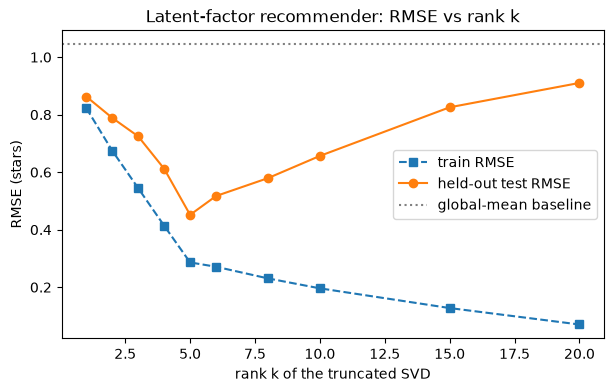

In [21]:
# ---- synthetic ratings: 200 users x 100 items, true latent rank 4, 25% observed ----
g = np.random.default_rng(0)
n_users, n_items, k_true = 200, 100, 4
P_true = g.normal(size=(n_users, k_true))
Q_true = g.normal(size=(n_items, k_true))
user_bias = g.normal(0, 0.5, size=n_users)
item_bias = g.normal(0, 0.5, size=n_items)
R_true = np.clip(3.5 + user_bias[:, None] + item_bias[None, :] + P_true @ Q_true.T / np.sqrt(k_true), 1, 5)
R_noisy = R_true + g.normal(0, 0.3, size=R_true.shape)
observed = g.random(R_true.shape) < 0.25           # which ratings exist
test_mask = observed & (g.random(R_true.shape) < 0.2)
train_mask = observed & ~test_mask
print(f"observed ratings: {observed.sum()} of {R_true.size} cells,"
      f" train {train_mask.sum()}, held-out test {test_mask.sum()}")


def impute_svd(R, mask, k, n_iter=30):
    mu = R[mask].mean()
    X = np.where(mask, R, mu)
    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        X_k = (U[:, :k] * s[:k]) @ Vt[:k]
        X = np.where(mask, R, X_k)           # keep observed ratings, update the gaps
    return X_k

def rmse(pred, R, mask):
    return float(np.sqrt(np.mean((pred[mask] - R[mask]) ** 2)))

ks = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
train_rmse, test_rmse = [], []
for k in ks:
    pred = impute_svd(R_noisy, train_mask, k)
    train_rmse.append(rmse(pred, R_noisy, train_mask))
    test_rmse.append(rmse(pred, R_noisy, test_mask))
    print(f"k = {k:2d}: train RMSE {train_rmse[-1]:.3f}   test RMSE {test_rmse[-1]:.3f}")

baseline = rmse(np.full_like(R_noisy, R_noisy[train_mask].mean()), R_noisy, test_mask)
best = ks[int(np.argmin(test_rmse))]
print(f"\nglobal-mean baseline test RMSE: {baseline:.3f}")
print(f"best rank k = {best} with test RMSE {min(test_rmse):.3f}  (true latent rank 4 + biases)")

plt.plot(ks, train_rmse, "s--", label="train RMSE")
plt.plot(ks, test_rmse, "o-", label="held-out test RMSE")
plt.axhline(baseline, color="gray", ls=":", label="global-mean baseline")
plt.title("Latent-factor recommender: RMSE vs rank k")
plt.xlabel("rank k of the truncated SVD"); plt.ylabel("RMSE (stars)"); plt.legend(); plt.show()

## Score

In [22]:
summary()


Score: 48/48 checks passed  🎉
